In [1]:
import numpy as np
import pandas as pd

# Reproducible random values
rng = np.random.default_rng(42)

# Generate 1000 households
n = 1000

num_occupants = rng.integers(1, 7, n)
avg_temperature = rng.uniform(0, 30, n)
house_size = rng.uniform(40, 250, n)

# Synthetic monthly electricity consumption
energy_consumption = (
    100
    + num_occupants * 65
    + house_size * 1.8
    + np.maximum(18 - avg_temperature, 0) * 12
    + rng.normal(0, 35, n)
)

# Create a DataFrame
df = pd.DataFrame({
    "num_occupants": num_occupants,
    "avg_temperature": avg_temperature,
    "house_size": house_size,
    "energy_consumption": energy_consumption
})

df.head()

,num_occupants,avg_temperature,house_size,energy_consumption
0,1,22.101171,181.089380,477.797237
1,5,26.592087,241.723262,844.069009
2,4,27.631716,117.891588,599.118663
3,3,15.108988,129.267171,591.041701
4,3,15.608253,210.545822,683.955388


In [10]:
print("Dataset shape:", df.shape)

print("\nColumn information:"), df.info()

print("\nStatistical summary:"), display(df.describe())

print("nMissing values:")

print(df.isnull().sum())

Dataset shape: (1000, 4)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   num_occupants       1000 non-null   int64  
 1   avg_temperature     1000 non-null   float64
 2   house_size          1000 non-null   float64
 3   energy_consumption  1000 non-null   float64
dtypes: float64(3), int64(1)
memory usage: 31.4 KB

Statistical summary:


,num_occupants,avg_temperature,house_size,energy_consumption
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,3.488000,15.048735,144.770226,653.850320
std,1.719539,8.818192,60.656099,175.410137
min,1.000000,0.015562,40.119307,190.379411
25%,2.000000,7.309493,92.478659,539.946364
50%,4.000000,14.804431,143.458512,648.862769
75%,5.000000,22.880050,198.781013,775.787356
max,6.000000,29.982657,249.950721,1178.535598


nMissing values:
num_occupants         0
avg_temperature       0
house_size            0
energy_consumption    0
dtype: int64


In [11]:
df.to_csv("energy_data.csv",index=False)
print("Dataset saved succesfully!")

Dataset saved succesfully!


In [12]:
df.head(10)

,num_occupants,avg_temperature,house_size,energy_consumption
0,1,22.101171,181.089380,477.797237
1,5,26.592087,241.723262,844.069009
2,4,27.631716,117.891588,599.118663
3,3,15.108988,129.267171,591.041701
4,3,15.608253,210.545822,683.955388
5,6,23.996112,146.210086,739.067461
6,1,9.433521,194.680350,637.161960
7,5,25.121471,136.538988,641.804729
8,2,14.824249,85.253980,407.197481
9,1,3.475702,196.492807,696.114379


In [14]:
df.shape

(1000, 4)

In [15]:
df.describe()

,num_occupants,avg_temperature,house_size,energy_consumption
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,3.488000,15.048735,144.770226,653.850320
std,1.719539,8.818192,60.656099,175.410137
min,1.000000,0.015562,40.119307,190.379411
25%,2.000000,7.309493,92.478659,539.946364
50%,4.000000,14.804431,143.458512,648.862769
75%,5.000000,22.880050,198.781013,775.787356
max,6.000000,29.982657,249.950721,1178.535598


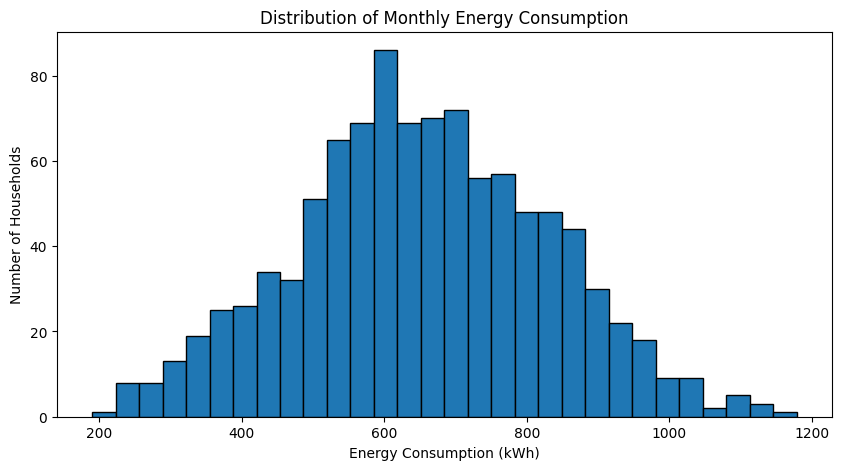

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df["energy_consumption"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Monthly Energy Consumption")
plt.xlabel("Energy Consumption (kWh)")
plt.ylabel("Number of Households")

plt.show()

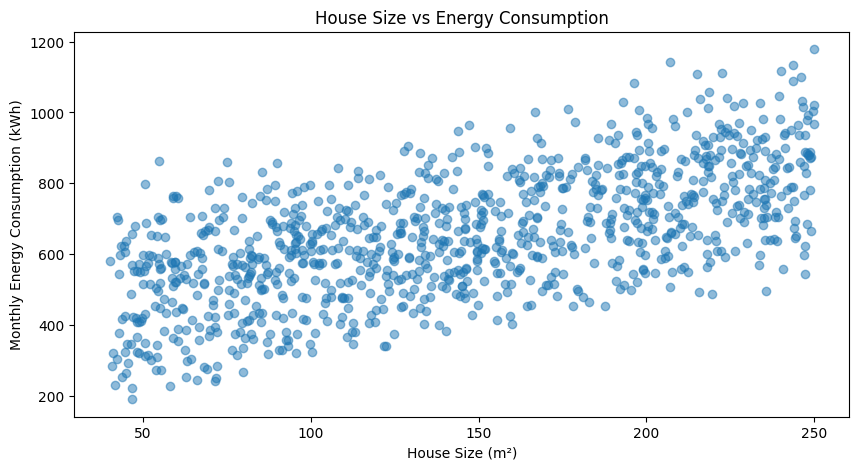

In [17]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["house_size"],
    df["energy_consumption"],
    alpha=0.5
)

plt.title("House Size vs Energy Consumption")
plt.xlabel("House Size (m²)")
plt.ylabel("Monthly Energy Consumption (kWh)")

plt.show()

In [18]:
correlation = df.corr(numeric_only=True)

print(correlation)

                    num_occupants  avg_temperature  house_size  \
num_occupants            1.000000        -0.006800   -0.003029   
avg_temperature         -0.006800         1.000000    0.010600   
house_size              -0.003029         0.010600    1.000000   
energy_consumption       0.634829        -0.380178    0.624389   

                    energy_consumption  
num_occupants                 0.634829  
avg_temperature              -0.380178  
house_size                    0.624389  
energy_consumption            1.000000  


In [21]:
print(df.isnull().sum())

num_occupants         0
avg_temperature       0
house_size            0
energy_consumption    0
dtype: int64


In [22]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [23]:
X = df[
    ["num_occupants", "avg_temperature", "house_size"]
]

y = df["energy_consumption"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (1000, 3)
Target: (1000,)


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (800, 3)
Testing features: (200, 3)
Training targets: (800,)
Testing targets: (200,)


In [25]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

print(model)

RandomForestRegressor(random_state=42)


In [27]:
model.fit(X_train, y_train)
print("Model trained succesfully!")

Model trained succesfully!


In [29]:
y_pred = model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[262.53107046 544.13177269 640.21970749 653.32780773 355.88276082
 688.26592479 529.13122516 676.28110658 710.10587628 615.39964827]


In [30]:
import pandas as pd

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison["Error"] = (
    comparison["Actual"] - comparison["Predicted"]
)

display(comparison.head(10))

,Actual,Predicted,Error
0,254.219606,262.531070,-8.311465
1,571.608699,544.131773,27.476926
2,574.877810,640.219707,-65.341898
3,701.426231,653.327808,48.098423
4,373.928160,355.882761,18.045399
5,674.625257,688.265925,-13.640667
6,475.880691,529.131225,-53.250534
7,732.010290,676.281107,55.729184
8,728.986507,710.105876,18.880631
9,581.424365,615.399648,-33.975283


In [31]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 2), "kWh")

Mean Absolute Error: 32.01 kWh


In [32]:
import numpy as np
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

print("Root Mean Squared Error:", round(rmse, 2), "kWh")


Root Mean Squared Error: 41.13 kWh


In [33]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R-squared:", round(r2, 4))

R-squared: 0.9419


In [34]:
print("MODEL EVALUATION RESULTS")
print("------------------------")

print(f"MAE:  {mae:.2f} kWh")
print(f"RMSE: {rmse:.2f} kWh")
print(f"R²:   {r2:.4f}")

MODEL EVALUATION RESULTS
------------------------
MAE:  32.01 kWh
RMSE: 41.13 kWh
R²:   0.9419


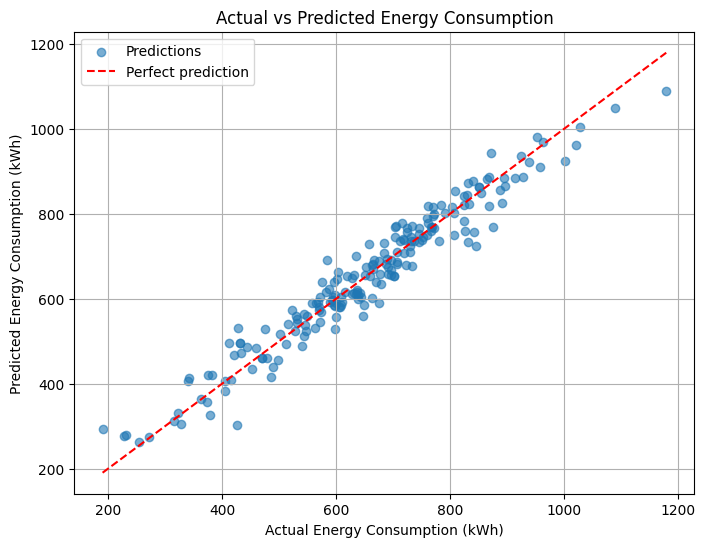

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6,
    label="Predictions"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Energy Consumption (kWh)")
plt.ylabel("Predicted Energy Consumption (kWh)")
plt.title("Actual vs Predicted Energy Consumption")

plt.legend()
plt.grid(True)
plt.show()

In [36]:
import joblib

joblib.dump(model, "energy_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [38]:
loaded_model = joblib.load("energy_model.joblib")
print("MOdel loaded succesfully!")

MOdel loaded succesfully!


In [39]:
import pandas as pd

new_house = pd.DataFrame({
    "num_occupants": [4],
    "avg_temperature": [15],
    "house_size": [120]
})

prediction = loaded_model.predict(new_house)

print(
    f"Predicted monthly energy consumption: "
    f"{prediction[0]:.2f} kWh"
)

Predicted monthly energy consumption: 613.03 kWh


In [40]:
original_prediction = model.predict(new_house)

loaded_prediction = loaded_model.predict(new_house)

print("Original model:", original_prediction[0])
print("Loaded model:", loaded_prediction[0])

Original model: 613.0250659431316
Loaded model: 613.0250659431316


In [41]:
import os
print(os.getcwd())
print(os.listdir())

C:\Windows\System32\EnergyConsumptionAI
['.ipynb_checkpoints', 'energy_analysis.ipynb', 'energy_data.csv', 'energy_model.joblib', 'main.py', 'ndex.html', '__pycache__']


In [42]:
from pathlib import Path

html_file = Path("index.html")

print("HTML file exists:", html_file.exists())
print("File size:", html_file.stat().st_size if html_file.exists() else "Not found")

HTML file exists: True
File size: 3994


In [43]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8000/",
        timeout=5
    )

    print("Status code:", response.status_code)
    print("Response:", response.text[:200])

except requests.exceptions.RequestException as error:
    print("Connection error:", error)

Connection error: HTTPConnectionPool(host='127.0.0.1', port=8000): Read timed out. (read timeout=5)


In [44]:
import fastapi
import uvicorn
import pandas
import numpy
import sklearn
import joblib

print("FastAPI:", fastapi.__version__)
print("Uvicorn:", uvicorn.__version__)
print("Pandas:", pandas.__version__)
print("NumPy:", numpy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

FastAPI: 0.164.0
Uvicorn: 0.54.0
Pandas: 2.2.3
NumPy: 2.2.5
Scikit-learn: 1.7.0
Joblib: 1.5.1


In [45]:
import fastapi
import uvicorn
import pandas
import numpy
import sklearn
import joblib

print("FastAPI:", fastapi.__version__)
print("Uvicorn:", uvicorn.__version__)
print("Pandas:", pandas.__version__)
print("NumPy:", numpy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

FastAPI: 0.164.0
Uvicorn: 0.54.0
Pandas: 2.2.3
NumPy: 2.2.5
Scikit-learn: 1.7.0
Joblib: 1.5.1
